Here is the Start of the XGBoost Model

In [ ]:
import torch
torch.manual_seed(42)

In [ ]:
# ============================================================
# STEP 1: Install required libraries
# ============================================================
!pip install xgboost torch_geometric pygod

In [ ]:
# ============================================================
# STEP 2: Mount Google Drive so Colab can access your uploaded dataset
# ============================================================
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# ============================================================
# STEP 3: Locate the fraud dataset zip file anywhere in your Drive
# ============================================================
import os

for root, dirs, files in os.walk('/content/drive/MyDrive'):
    for f in files:
        if 'fraud' in f.lower() and f.lower().endswith('.zip'):
            print(os.path.join(root, f))


/content/drive/MyDrive/fraudTest.csv.zip


In [ ]:
# ============================================================
# STEP 4: Unzip the dataset into Colab's local storage
# (update zip_path below if Step 3 printed a different path)
# ============================================================
import zipfile

zip_path = "/content/drive/MyDrive/fraudTest.csv.zip"
extract_path = "/content/fraud_data"

os.makedirs(extract_path, exist_ok=True)
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print(os.listdir(extract_path))  # confirms the extracted filename


['fraudTest.csv']


In [ ]:
# ============================================================
# STEP 5: Load the dataset into a pandas DataFrame
# ============================================================
import pandas as pd

df = pd.read_csv("/content/fraud_data/fraudTest.csv")

print("Full dataset shape:", df.shape)      # (555719, 23) — this IS the full file
print("Total rows:", len(df))
df.head()   # preview only shows first 5 rows — this is normal, not a bug

Full dataset shape: (555719, 23)
Total rows: 555719


,Unnamed: 0,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,...,lat,long,city_pop,job,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud
0,0,2020-06-21 12:14:25,2291163933867244,fraud_Kirlin and Sons,personal_care,2.86,Jeff,Elliott,M,351 Darlene Green,...,33.9659,-80.9355,333497,Mechanical engineer,1968-03-19,2da90c7d74bd46a0caf3777415b3ebd3,1371816865,33.986391,-81.200714,0
1,1,2020-06-21 12:14:33,3573030041201292,fraud_Sporer-Keebler,personal_care,29.84,Joanne,Williams,F,3638 Marsh Union,...,40.3207,-110.4360,302,"Sales professional, IT",1990-01-17,324cc204407e99f51b0d6ca0055005e7,1371816873,39.450498,-109.960431,0
2,2,2020-06-21 12:14:53,3598215285024754,"fraud_Swaniawski, Nitzsche and Welch",health_fitness,41.28,Ashley,Lopez,F,9333 Valentine Point,...,40.6729,-73.5365,34496,"Librarian, public",1970-10-21,c81755dbbbea9d5c77f094348a7579be,1371816893,40.495810,-74.196111,0
3,3,2020-06-21 12:15:15,3591919803438423,fraud_Haley Group,misc_pos,60.05,Brian,Williams,M,32941 Krystal Mill Apt. 552,...,28.5697,-80.8191,54767,Set designer,1987-07-25,2159175b9efe66dc301f149d3d5abf8c,1371816915,28.812398,-80.883061,0
4,4,2020-06-21 12:15:17,3526826139003047,fraud_Johnston-Casper,travel,3.19,Nathan,Massey,M,5783 Evan Roads Apt. 465,...,44.2529,-85.0170,1126,Furniture designer,1955-07-06,57ff021bd3f328f8738bb535c302a31b,1371816917,44.959148,-85.884734,0


In [ ]:
# ============================================================
# STEP 6: Clean the dataset
# ============================================================
import numpy as np

# --- Drop columns that don't belong as ML features ---
# 'Unnamed: 0' = leftover index column from the CSV
# 'first', 'last', 'street' = identifying info, not predictive
# 'trans_num' = unique ID, not a feature
# 'unix_time' = redundant, we already have trans_date_trans_time
df = df.drop(columns=['Unnamed: 0', 'first', 'last', 'street', 'trans_num', 'unix_time'])

# --- Convert timestamp and extract useful time-based features ---
df['trans_date_trans_time'] = pd.to_datetime(df['trans_date_trans_time'])
df['hour'] = df['trans_date_trans_time'].dt.hour
df['day_of_week'] = df['trans_date_trans_time'].dt.dayofweek
df['month'] = df['trans_date_trans_time'].dt.month

# --- Compute customer age from date of birth ---
df['dob'] = pd.to_datetime(df['dob'])
df['age'] = (df['trans_date_trans_time'] - df['dob']).dt.days // 365

# --- Compute distance between customer and merchant (fraud signal) ---
def haversine(lat1, lon1, lat2, lon2):
    """Great-circle distance in km between two lat/long points."""
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    dlat, dlon = lat2 - lat1, lon2 - lon1
    a = np.sin(dlat/2)**2 + np.cos(lat1)*np.cos(lat2)*np.sin(dlon/2)**2
    return 2 * 6371 * np.arcsin(np.sqrt(a))

df['distance_km'] = haversine(df['lat'], df['long'], df['merch_lat'], df['merch_long'])

# --- Check data quality ---
print("Missing values:\n", df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
df = df.drop_duplicates()

# --- Encode categorical columns into numeric form ---
df['gender'] = df['gender'].map({'M': 0, 'F': 1})
df = pd.get_dummies(df, columns=['category'], prefix='cat')

# --- Verify the categories are legitimate (not typos/artifacts) ---
print("\nCategories found:", df.filter(like='cat_').columns.tolist())

# --- Sort chronologically (needed later for the temporal split) ---
df = df.sort_values('trans_date_trans_time').reset_index(drop=True)

print("\nFinal cleaned shape:", df.shape)
print("Fraud rate:", df['is_fraud'].mean())
df.head()


Missing values:
 trans_date_trans_time    0
cc_num                   0
merchant                 0
category                 0
amt                      0
gender                   0
city                     0
state                    0
zip                      0
lat                      0
long                     0
city_pop                 0
job                      0
dob                      0
merch_lat                0
merch_long               0
is_fraud                 0
hour                     0
day_of_week              0
month                    0
age                      0
distance_km              0
dtype: int64

Duplicate rows: 0

Categories found: ['cat_entertainment', 'cat_food_dining', 'cat_gas_transport', 'cat_grocery_net', 'cat_grocery_pos', 'cat_health_fitness', 'cat_home', 'cat_kids_pets', 'cat_misc_net', 'cat_misc_pos', 'cat_personal_care', 'cat_shopping_net', 'cat_shopping_pos', 'cat_travel']

Final cleaned shape: (555719, 35)
Fraud rate: 0.0038598644278853163


,trans_date_trans_time,cc_num,merchant,amt,gender,city,state,zip,lat,long,...,cat_grocery_pos,cat_health_fitness,cat_home,cat_kids_pets,cat_misc_net,cat_misc_pos,cat_personal_care,cat_shopping_net,cat_shopping_pos,cat_travel
0,2020-06-21 12:14:25,2291163933867244,fraud_Kirlin and Sons,2.86,0,Columbia,SC,29209,33.9659,-80.9355,...,False,False,False,False,False,False,True,False,False,False
1,2020-06-21 12:14:33,3573030041201292,fraud_Sporer-Keebler,29.84,1,Altonah,UT,84002,40.3207,-110.4360,...,False,False,False,False,False,False,True,False,False,False
2,2020-06-21 12:14:53,3598215285024754,"fraud_Swaniawski, Nitzsche and Welch",41.28,1,Bellmore,NY,11710,40.6729,-73.5365,...,False,True,False,False,False,False,False,False,False,False
3,2020-06-21 12:15:15,3591919803438423,fraud_Haley Group,60.05,0,Titusville,FL,32780,28.5697,-80.8191,...,False,False,False,False,False,True,False,False,False,False
4,2020-06-21 12:15:17,3526826139003047,fraud_Johnston-Casper,3.19,0,Falmouth,MI,49632,44.2529,-85.0170,...,False,False,False,False,False,False,False,False,False,True


In [ ]:
# ============================================================
# STEP 7: Split BEFORE computing aggregate features
# (critical — aggregates must be learned only from training data,
#  otherwise test-set information leaks into the features)
# ============================================================
from sklearn.model_selection import train_test_split

# Split at the row level first, keeping ALL columns for now
train_df, test_df = train_test_split(
    df, test_size=0.2, random_state=42, stratify=df['is_fraud']
)

print("Train shape:", train_df.shape, "| Fraud rate:", train_df['is_fraud'].mean())
print("Test shape:", test_df.shape, "| Fraud rate:", test_df['is_fraud'].mean())

Train shape: (444575, 35) | Fraud rate: 0.003859866164314233
Test shape: (111144, 35) | Fraud rate: 0.003859857482185273


In [ ]:
# ============================================================
# STEP 8: Engineer card-level features (from cc_num) — TRAIN ONLY
# ============================================================
# For each card, compute: how many transactions it made, its average
# amount, and how many distinct merchants it used — all learned
# purely from the training set.
card_stats = train_df.groupby('cc_num').agg(
    card_txn_count=('amt', 'count'),
    card_avg_amt=('amt', 'mean'),
    card_unique_merchants=('merchant', 'nunique')
).reset_index()

In [ ]:
# ============================================================
# STEP 9: Engineer merchant-level features — TRAIN ONLY
# ============================================================
# For each merchant: how many transactions it received, and its
# historical fraud rate (a strong signal — some merchants attract
# far more fraud than others).
merchant_stats = train_df.groupby('merchant').agg(
    merchant_txn_count=('amt', 'count'),
    merchant_fraud_rate=('is_fraud', 'mean')
).reset_index()

In [ ]:
# Global fallback values for cards/merchants seen in test but NOT in train
# (this will happen — some cards/merchants only appear in the test period)
global_avg_amt = train_df['amt'].mean()
global_fraud_rate = train_df['is_fraud'].mean()

In [ ]:
# ============================================================
# STEP 10: Merge these engineered features onto BOTH train and test
# ============================================================
def add_engineered_features(data):
    data = data.merge(card_stats, on='cc_num', how='left')
    data = data.merge(merchant_stats, on='merchant', how='left')

    # Fill in fallback values for any card/merchant not seen during training
    data['card_txn_count'] = data['card_txn_count'].fillna(0)
    data['card_avg_amt'] = data['card_avg_amt'].fillna(global_avg_amt)
    data['card_unique_merchants'] = data['card_unique_merchants'].fillna(0)
    data['merchant_txn_count'] = data['merchant_txn_count'].fillna(0)
    data['merchant_fraud_rate'] = data['merchant_fraud_rate'].fillna(global_fraud_rate)

    return data

train_df = add_engineered_features(train_df)
test_df = add_engineered_features(test_df)

print("\nEngineered features added. New columns:")
print(['card_txn_count', 'card_avg_amt', 'card_unique_merchants',
       'merchant_txn_count', 'merchant_fraud_rate'])


Engineered features added. New columns:
['card_txn_count', 'card_avg_amt', 'card_unique_merchants', 'merchant_txn_count', 'merchant_fraud_rate']


In [ ]:
# ============================================================
# STEP 11: Build the final XGBoost feature set
# (raw identity columns like cc_num/merchant are still excluded —
#  only their ENGINEERED, aggregate versions go into the model)
# ============================================================
xgb_features = [
    'amt', 'hour', 'day_of_week', 'month', 'age', 'distance_km',
    'city_pop', 'gender',
    'card_txn_count', 'card_avg_amt', 'card_unique_merchants',
    'merchant_txn_count', 'merchant_fraud_rate'
] + [c for c in df.columns if c.startswith('cat_')]

X_train = train_df[xgb_features]
y_train = train_df['is_fraud']
X_test = test_df[xgb_features]
y_test = test_df['is_fraud']

print("\nFinal X_train shape:", X_train.shape)
print("Final X_test shape:", X_test.shape)


Final X_train shape: (444575, 27)
Final X_test shape: (111144, 27)


In [ ]:
# ============================================================
# STEP 12: Train XGBoost on the improved feature set
# ============================================================
from xgboost import XGBClassifier

model = XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    scale_pos_weight=(y_train == 0).sum() / (y_train == 1).sum(),
    eval_metric='aucpr',
    random_state=42
)

model.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='aucpr', feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.1, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=6,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=200,
              n_jobs=None, num_parallel_tree=None, ...)

In [ ]:
# ============================================================
# STEP 13: Evaluate — this is your NEW, fairer baseline
# ============================================================
from sklearn.metrics import classification_report, average_precision_score, roc_auc_score

y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred, digits=3))
print("PR-AUC:", average_precision_score(y_test, y_prob))
print("ROC-AUC:", roc_auc_score(y_test, y_prob))

              precision    recall  f1-score   support

           0      0.999     0.997     0.998    110715
           1      0.518     0.862     0.647       429

    accuracy                          0.996    111144
   macro avg      0.759     0.930     0.823    111144
weighted avg      0.998     0.996     0.997    111144

PR-AUC: 0.8609952169851381
ROC-AUC: 0.9897435265813534


Here is the Work for the GNN

In [ ]:
# ============================================================
# STEP 14: Build node ID mappings for customers and merchants
# (every unique cc_num and merchant gets a single integer node ID)
# ============================================================
import torch
import numpy as np

all_customers = df['cc_num'].unique()
all_merchants = df['merchant'].unique()

customer_id_map = {cc: i for i, cc in enumerate(all_customers)}
merchant_id_map = {m: i + len(all_customers) for i, m in enumerate(all_merchants)}
# merchant node IDs continue right after customer node IDs, so all nodes
# share one combined ID space: [0 ... n_customers-1, n_customers ... n_customers+n_merchants-1]

num_customer_nodes = len(all_customers)
num_merchant_nodes = len(all_merchants)
num_nodes = num_customer_nodes + num_merchant_nodes

print("Customer nodes:", num_customer_nodes)
print("Merchant nodes:", num_merchant_nodes)
print("Total nodes:", num_nodes)

# ============================================================
# STEP 15: Build simple node features
# Customer node feature = [card_avg_amt, card_txn_count, card_unique_merchants, is_customer_flag]
# Merchant node feature = [merchant_avg_amt, merchant_txn_count, merchant_fraud_rate, is_customer_flag]
# (computed from TRAIN data only, same leakage-avoidance rule as before)
# ============================================================
merchant_avg_amt_stats = train_df.groupby('merchant')['amt'].mean()

customer_node_feats = np.zeros((num_customer_nodes, 4))
for cc, node_id in customer_id_map.items():
    row = card_stats[card_stats['cc_num'] == cc]
    if len(row) > 0:
        customer_node_feats[node_id] = [
            row['card_avg_amt'].values[0],
            row['card_txn_count'].values[0],
            row['card_unique_merchants'].values[0],
            1.0  # is_customer flag
        ]
    else:
        customer_node_feats[node_id] = [global_avg_amt, 0, 0, 1.0]

merchant_node_feats = np.zeros((num_merchant_nodes, 4))
for m, node_id in merchant_id_map.items():
    local_id = node_id - num_customer_nodes
    row = merchant_stats[merchant_stats['merchant'] == m]
    if len(row) > 0:
        merchant_node_feats[local_id] = [
            row['merchant_txn_count'].values[0],
            row['merchant_fraud_rate'].values[0],
            merchant_avg_amt_stats.get(m, global_avg_amt),
            0.0  # is_customer flag = 0, this is a merchant
        ]
    else:
        merchant_node_feats[local_id] = [0, global_fraud_rate, global_avg_amt, 0.0]

node_features = np.vstack([customer_node_feats, merchant_node_feats])
x = torch.tensor(node_features, dtype=torch.float)
print("Node feature matrix shape:", x.shape)

Customer nodes: 924
Merchant nodes: 693
Total nodes: 1617
Node feature matrix shape: torch.Size([1617, 4])


In [ ]:
# ============================================================
# STEP 16: Build edges — one edge per transaction, connecting
# that transaction's customer node to its merchant node
# ============================================================
customer_idx = df['cc_num'].map(customer_id_map).values
merchant_idx = df['merchant'].map(merchant_id_map).values

# edge_index shape: [2, num_edges] — row 0 = source (customer), row 1 = target (merchant)
edge_index = torch.tensor(np.vstack([customer_idx, merchant_idx]), dtype=torch.long)

print("Edge index shape:", edge_index.shape)  # should be [2, 555719]

# ============================================================
# STEP 17: Build edge features
# Same transaction-level features XGBoost used — keeps the
# comparison fair (same information, different structure)
# ============================================================
edge_feature_cols = [
    'amt', 'hour', 'day_of_week', 'month', 'age', 'distance_km'
] + [c for c in df.columns if c.startswith('cat_')]

edge_attr = torch.tensor(df[edge_feature_cols].values.astype(np.float32), dtype=torch.float)

print("Edge feature matrix shape:", edge_attr.shape)

# ============================================================
# STEP 18: Edge labels (is this transaction fraud?)
# ============================================================
edge_label = torch.tensor(df['is_fraud'].values, dtype=torch.long)

# ============================================================
# STEP 19: Reuse the SAME train/test split as XGBoost
# (train_df/test_df already exist from Step 7 — this keeps the
# comparison fair, both models judged on identical data)
# ============================================================
train_idx_set = set(train_df.index)
test_idx_set = set(test_df.index)

train_mask = torch.tensor(df.index.isin(train_idx_set), dtype=torch.bool)
test_mask = torch.tensor(df.index.isin(test_idx_set), dtype=torch.bool)

print("Train edges:", train_mask.sum().item())
print("Test edges:", test_mask.sum().item())

# ============================================================
# STEP 20: Assemble everything into a single PyG Data object
# ============================================================
from torch_geometric.data import Data

data = Data(x=x, edge_index=edge_index, edge_attr=edge_attr)
data.edge_label = edge_label
data.train_mask = train_mask
data.test_mask = test_mask

print(data)

Edge index shape: torch.Size([2, 555719])
Edge feature matrix shape: torch.Size([555719, 20])
Train edges: 444575
Test edges: 111144
Data(x=[1617, 4], edge_index=[2, 555719], edge_attr=[555719, 20], edge_label=[555719], train_mask=[555719], test_mask=[555719])


In [ ]:
# ============================================================
# Imports needed for the model (previously in the old Step 21,
# keep this even though that cell was deleted)
# ============================================================
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.nn import SAGEConv

# ============================================================
# STEP 21a: Normalize node and edge features (fit on TRAIN only)
# ============================================================
from sklearn.preprocessing import StandardScaler

# --- Scale edge features ---
edge_scaler = StandardScaler()
train_edge_feats = df.loc[train_df.index, edge_feature_cols].values
edge_scaler.fit(train_edge_feats)

edge_attr_scaled = edge_scaler.transform(df[edge_feature_cols].values)
edge_attr = torch.tensor(edge_attr_scaled, dtype=torch.float)

# --- Scale node features ---
node_scaler = StandardScaler()
node_scaler.fit(node_features)  # fine here since node stats already came from train_df only
node_features_scaled = node_scaler.transform(node_features)
x = torch.tensor(node_features_scaled, dtype=torch.float)

print("Edge features scaled — mean/std check:", edge_attr.mean().item(), edge_attr.std().item())
print("Node features scaled — mean/std check:", x.mean().item(), x.std().item())

# ============================================================
# STEP 21b: Rebuild the Data object with scaled features
# ============================================================
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

data = Data(x=x, edge_index=edge_index, edge_attr=edge_attr)
data.edge_label = edge_label
data.train_mask = train_mask
data.test_mask = test_mask
data = data.to(device)

print("Using device:", device)

# ============================================================
# STEP 21c: Build an undirected version of the graph for
# message passing (structure only — lets info flow both ways)
# ============================================================
from torch_geometric.utils import to_undirected

structure_edge_index = to_undirected(edge_index)
data.structure_edge_index = structure_edge_index.to(device)

print("Original directed edges:", edge_index.shape[1])
print("Undirected structure edges:", structure_edge_index.shape[1])



# ============================================================
# STEP 22a: Update the model to use two edge indices —
# one for graph convolution (undirected), one for the actual
# per-transaction prediction (original directed edges)
# ============================================================
class FraudGraphSAGE(nn.Module):
    def __init__(self, node_in_channels, edge_in_channels, hidden_channels):
        super().__init__()
        self.conv1 = SAGEConv(node_in_channels, hidden_channels)
        self.conv2 = SAGEConv(hidden_channels, hidden_channels)
        self.edge_classifier = nn.Sequential(
            nn.Linear(hidden_channels * 2 + edge_in_channels, hidden_channels),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(hidden_channels, 2)
        )

    def forward(self, x, structure_edge_index, edge_index, edge_attr):
        # Message passing uses the UNDIRECTED structure edges
        h = self.conv1(x, structure_edge_index)
        h = F.relu(h)
        h = F.dropout(h, p=0.3, training=self.training)
        h = self.conv2(h, structure_edge_index)

        # Prediction uses the ORIGINAL per-transaction directed edges
        src, dst = edge_index
        edge_embeds = torch.cat([h[src], h[dst], edge_attr], dim=1)
        return self.edge_classifier(edge_embeds)

model = FraudGraphSAGE(
    node_in_channels=x.shape[1],
    edge_in_channels=edge_attr.shape[1],
    hidden_channels=64
).to(device)

optimizer = torch.optim.Adam(model.parameters(), lr=0.005, weight_decay=5e-4)

Edge features scaled — mean/std check: 0.017482692375779152 1.0132726430892944
Node features scaled — mean/std check: -2.683499111810761e-08 1.0000773668289185
Using device: cpu
Original directed edges: 555719
Undirected structure edges: 656792


In [ ]:
# ============================================================
# Class imbalance weight (previously in the old Step 22, keep
# this even though that cell was deleted)
# ============================================================
class_weights = torch.tensor(
    [1.0, (data.edge_label[data.train_mask] == 0).sum().item() /
          (data.edge_label[data.train_mask] == 1).sum().item()],
    dtype=torch.float
).to(device)

print("Class weights:", class_weights)

# ============================================================
# STEP 23a: Training loop (updated forward call)
# ============================================================
criterion = nn.CrossEntropyLoss(weight=class_weights)

def train_epoch():
    model.train()
    optimizer.zero_grad()
    out = model(data.x, data.structure_edge_index, data.edge_index, data.edge_attr)
    loss = criterion(out[data.train_mask], data.edge_label[data.train_mask])
    loss.backward()
    optimizer.step()
    return loss.item()

print("Starting training...")
for epoch in range(1, 51):
    loss = train_epoch()
    if epoch % 5 == 0 or epoch == 1:
        print(f"Epoch {epoch:3d} | Loss: {loss:.4f}")
print("Training done.")

Class weights: tensor([  1.0000, 225.7083])
Starting training...
Epoch   1 | Loss: 0.7128
Epoch   5 | Loss: 0.5402
Epoch  10 | Loss: 0.4615
Epoch  15 | Loss: 0.4234
Epoch  20 | Loss: 0.3902
Epoch  25 | Loss: 0.3647
Epoch  30 | Loss: 0.3443
Epoch  35 | Loss: 0.3262
Epoch  40 | Loss: 0.3140
Epoch  45 | Loss: 0.3042
Epoch  50 | Loss: 0.2958
Training done.


In [ ]:
# ============================================================
# STEP 23b: Train longer to see if it actually converges
# ============================================================
print("Continuing training...")
for epoch in range(1, 201):
    loss = train_epoch()
    if epoch % 20 == 0:
        print(f"Epoch {epoch:3d} | Loss: {loss:.4f}")
print("Training done.")

Continuing training...
Epoch  20 | Loss: 0.2579
Epoch  40 | Loss: 0.2319
Epoch  60 | Loss: 0.2088
Epoch  80 | Loss: 0.1891
Epoch 100 | Loss: 0.1724
Epoch 120 | Loss: 0.1617
Epoch 140 | Loss: 0.1511
Epoch 160 | Loss: 0.1452
Epoch 180 | Loss: 0.1335
Epoch 200 | Loss: 0.1316
Training done.


In [ ]:
# ============================================================
# STEP 24a: Evaluate (updated forward call)
# ============================================================
model.eval()
with torch.no_grad():
    out = model(data.x, data.structure_edge_index, data.edge_index, data.edge_attr)
    probs = F.softmax(out, dim=1)[:, 1]

test_labels = data.edge_label[data.test_mask].cpu().numpy()
test_probs = probs[data.test_mask].cpu().numpy()
test_preds = (test_probs >= 0.5).astype(int)

print(classification_report(test_labels, test_preds, digits=3))
print("PR-AUC:", average_precision_score(test_labels, test_probs))
print("ROC-AUC:", roc_auc_score(test_labels, test_probs))

              precision    recall  f1-score   support

           0      1.000     0.960     0.980    110714
           1      0.087     0.977     0.159       430

    accuracy                          0.960    111144
   macro avg      0.543     0.968     0.569    111144
weighted avg      0.996     0.960     0.976    111144

PR-AUC: 0.7477135804126156
ROC-AUC: 0.9953206900999054


In [ ]:
# ============================================================
# STEP 25: Check the date range to decide the temporal cutoff
# ============================================================
print("Earliest transaction:", df['trans_date_trans_time'].min())
print("Latest transaction:", df['trans_date_trans_time'].max())
print("\nTransactions per month:")
print(df['trans_date_trans_time'].dt.to_period('M').value_counts().sort_index())


Earliest transaction: 2020-06-21 12:14:25
Latest transaction: 2020-12-31 23:59:34

Transactions per month:
trans_date_trans_time
2020-06     30058
2020-07     85848
2020-08     88759
2020-09     69533
2020-10     69348
2020-11     72635
2020-12    139538
Freq: M, Name: count, dtype: int64


In [ ]:
# ============================================================
# STEP 26: Find the exact date that splits the data 80/20 by time
# ============================================================
# df is already sorted chronologically from the cleaning step
cutoff_idx = int(len(df) * 0.8)
cutoff_date = df.iloc[cutoff_idx]['trans_date_trans_time']

print("Temporal cutoff date:", cutoff_date)
print("Transactions before cutoff:", (df['trans_date_trans_time'] < cutoff_date).sum())
print("Transactions on/after cutoff:", (df['trans_date_trans_time'] >= cutoff_date).sum())

# ============================================================
# STEP 27: Build the temporal train/test split
# ============================================================
temporal_train_df = df[df['trans_date_trans_time'] < cutoff_date].copy()
temporal_test_df = df[df['trans_date_trans_time'] >= cutoff_date].copy()

print("\nTemporal train shape:", temporal_train_df.shape, "| Fraud rate:", temporal_train_df['is_fraud'].mean())
print("Temporal test shape:", temporal_test_df.shape, "| Fraud rate:", temporal_test_df['is_fraud'].mean())

Temporal cutoff date: 2020-12-07 13:35:07
Transactions before cutoff: 444575
Transactions on/after cutoff: 111144

Temporal train shape: (444575, 35) | Fraud rate: 0.0044109542821796095
Temporal test shape: (111144, 35) | Fraud rate: 0.0016555099690491615


In [ ]:
# ============================================================
# STEP 28: Re-engineer card/merchant features — TEMPORAL TRAIN ONLY
# ============================================================
temporal_card_stats = temporal_train_df.groupby('cc_num').agg(
    card_txn_count=('amt', 'count'),
    card_avg_amt=('amt', 'mean'),
    card_unique_merchants=('merchant', 'nunique')
).reset_index()

temporal_merchant_stats = temporal_train_df.groupby('merchant').agg(
    merchant_txn_count=('amt', 'count'),
    merchant_fraud_rate=('is_fraud', 'mean')
).reset_index()

temporal_global_avg_amt = temporal_train_df['amt'].mean()
temporal_global_fraud_rate = temporal_train_df['is_fraud'].mean()

def add_temporal_features(data):
    data = data.merge(temporal_card_stats, on='cc_num', how='left')
    data = data.merge(temporal_merchant_stats, on='merchant', how='left')
    data['card_txn_count'] = data['card_txn_count'].fillna(0)
    data['card_avg_amt'] = data['card_avg_amt'].fillna(temporal_global_avg_amt)
    data['card_unique_merchants'] = data['card_unique_merchants'].fillna(0)
    data['merchant_txn_count'] = data['merchant_txn_count'].fillna(0)
    data['merchant_fraud_rate'] = data['merchant_fraud_rate'].fillna(temporal_global_fraud_rate)
    return data

temporal_train_df = add_temporal_features(temporal_train_df)
temporal_test_df = add_temporal_features(temporal_test_df)

print("Temporal features added.")
print("Train shape:", temporal_train_df.shape)
print("Test shape:", temporal_test_df.shape)

# ============================================================
# STEP 29: Build XGBoost feature sets for the temporal split
# ============================================================
X_train_temporal = temporal_train_df[xgb_features]
y_train_temporal = temporal_train_df['is_fraud']
X_test_temporal = temporal_test_df[xgb_features]
y_test_temporal = temporal_test_df['is_fraud']

# ============================================================
# STEP 30: Train XGBoost on the temporal split
# ============================================================
model_temporal = XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    scale_pos_weight=(y_train_temporal == 0).sum() / (y_train_temporal == 1).sum(),
    eval_metric='aucpr',
    random_state=42
)

model_temporal.fit(X_train_temporal, y_train_temporal)

# ============================================================
# STEP 31: Evaluate XGBoost on the temporal split
# ============================================================
y_pred_temporal = model_temporal.predict(X_test_temporal)
y_prob_temporal = model_temporal.predict_proba(X_test_temporal)[:, 1]

print(classification_report(y_test_temporal, y_pred_temporal, digits=3))
print("PR-AUC (temporal):", average_precision_score(y_test_temporal, y_prob_temporal))
print("ROC-AUC (temporal):", roc_auc_score(y_test_temporal, y_prob_temporal))

Temporal features added.
Train shape: (444575, 40)
Test shape: (111144, 40)
              precision    recall  f1-score   support

           0      0.999     0.998     0.999    110960
           1      0.341     0.560     0.424       184

    accuracy                          0.997    111144
   macro avg      0.670     0.779     0.711    111144
weighted avg      0.998     0.997     0.998    111144

PR-AUC (temporal): 0.46662489793940776
ROC-AUC (temporal): 0.9635190217391304


In [ ]:
# ============================================================
# STEP 32 (FIXED): Build temporal masks directly from df,
# guaranteed aligned with edge_index/edge_label row order
# ============================================================
temporal_train_mask = torch.tensor(
    (df['trans_date_trans_time'] < cutoff_date).values, dtype=torch.bool
)
temporal_test_mask = torch.tensor(
    (df['trans_date_trans_time'] >= cutoff_date).values, dtype=torch.bool
)

print("Temporal train edges:", temporal_train_mask.sum().item())
print("Temporal test edges:", temporal_test_mask.sum().item())
print("Fraud in temporal test (should be 184):", edge_label[temporal_test_mask].sum().item())

# ============================================================
# STEP 33: Rebuild node features using TEMPORAL train stats only
# (same 4-feature design as before, just recomputed to avoid leakage)
# ============================================================
temporal_merchant_avg_amt = temporal_train_df.groupby('merchant')['amt'].mean()

temporal_customer_feats = np.zeros((num_customer_nodes, 4))
for cc, node_id in customer_id_map.items():
    row = temporal_card_stats[temporal_card_stats['cc_num'] == cc]
    if len(row) > 0:
        temporal_customer_feats[node_id] = [
            row['card_avg_amt'].values[0],
            row['card_txn_count'].values[0],
            row['card_unique_merchants'].values[0],
            1.0
        ]
    else:
        temporal_customer_feats[node_id] = [temporal_global_avg_amt, 0, 0, 1.0]

temporal_merchant_feats = np.zeros((num_merchant_nodes, 4))
for m, node_id in merchant_id_map.items():
    local_id = node_id - num_customer_nodes
    row = temporal_merchant_stats[temporal_merchant_stats['merchant'] == m]
    if len(row) > 0:
        temporal_merchant_feats[local_id] = [
            row['merchant_txn_count'].values[0],
            row['merchant_fraud_rate'].values[0],
            temporal_merchant_avg_amt.get(m, temporal_global_avg_amt),
            0.0
        ]
    else:
        temporal_merchant_feats[local_id] = [0, temporal_global_fraud_rate, temporal_global_avg_amt, 0.0]

temporal_node_features = np.vstack([temporal_customer_feats, temporal_merchant_feats])

# ============================================================
# STEP 34: Scale features (fit scaler on TEMPORAL TRAIN only)
# ============================================================
temporal_edge_scaler = StandardScaler()
temporal_train_edge_feats = df.loc[temporal_train_df.index, edge_feature_cols].values
temporal_edge_scaler.fit(temporal_train_edge_feats)
temporal_edge_attr = torch.tensor(
    temporal_edge_scaler.transform(df[edge_feature_cols].values), dtype=torch.float
)

temporal_node_scaler = StandardScaler()
temporal_node_scaler.fit(temporal_node_features)
temporal_x = torch.tensor(
    temporal_node_scaler.transform(temporal_node_features), dtype=torch.float
)

# ============================================================
# STEP 35: Build the temporal Data object
# ============================================================
temporal_data = Data(x=temporal_x, edge_index=edge_index, edge_attr=temporal_edge_attr)
temporal_data.edge_label = edge_label
temporal_data.train_mask = temporal_train_mask
temporal_data.test_mask = temporal_test_mask
temporal_data = temporal_data.to(device)
temporal_data.structure_edge_index = to_undirected(edge_index).to(device)

print("Temporal data object ready:", temporal_data)

Temporal train edges: 444575
Temporal test edges: 111144
Fraud in temporal test (should be 184): 184
Temporal data object ready: Data(x=[1617, 4], edge_index=[2, 555719], edge_attr=[555719, 20], edge_label=[555719], train_mask=[555719], test_mask=[555719], structure_edge_index=[2, 656792])


In [ ]:
# ============================================================
# STEP 36: Build a FRESH model + class weights for the temporal split
# (new weights — this model should learn only from the earlier period)
# ============================================================
model_temporal_gnn = FraudGraphSAGE(
    node_in_channels=temporal_x.shape[1],
    edge_in_channels=temporal_edge_attr.shape[1],
    hidden_channels=64
).to(device)

optimizer_temporal = torch.optim.Adam(model_temporal_gnn.parameters(), lr=0.005, weight_decay=5e-4)

class_weights_temporal = torch.tensor(
    [1.0, (temporal_data.edge_label[temporal_data.train_mask] == 0).sum().item() /
          (temporal_data.edge_label[temporal_data.train_mask] == 1).sum().item()],
    dtype=torch.float
).to(device)

print("Temporal class weights:", class_weights_temporal)

# ============================================================
# STEP 37: Train the temporal GNN
# ============================================================
criterion_temporal = nn.CrossEntropyLoss(weight=class_weights_temporal)

def train_epoch_temporal():
    model_temporal_gnn.train()
    optimizer_temporal.zero_grad()
    out = model_temporal_gnn(
        temporal_data.x, temporal_data.structure_edge_index,
        temporal_data.edge_index, temporal_data.edge_attr
    )
    loss = criterion_temporal(out[temporal_data.train_mask], temporal_data.edge_label[temporal_data.train_mask])
    loss.backward()
    optimizer_temporal.step()
    return loss.item()

print("Starting temporal GNN training...")
for epoch in range(1, 201):
    loss = train_epoch_temporal()
    if epoch % 20 == 0 or epoch == 1:
        print(f"Epoch {epoch:3d} | Loss: {loss:.4f}")
print("Training done.")

# ============================================================
# STEP 38a: Evaluate the temporal GNN
# ============================================================
model_temporal_gnn.eval()
with torch.no_grad():
    out = model_temporal_gnn(
        temporal_data.x, temporal_data.structure_edge_index,
        temporal_data.edge_index, temporal_data.edge_attr
    )
    probs = F.softmax(out, dim=1)[:, 1]

test_labels_temporal = temporal_data.edge_label[temporal_data.test_mask].cpu().numpy()
test_probs_temporal = probs[temporal_data.test_mask].cpu().numpy()
test_preds_temporal = (test_probs_temporal >= 0.5).astype(int)

print(classification_report(test_labels_temporal, test_preds_temporal, digits=3))
print("PR-AUC (temporal GNN):", average_precision_score(test_labels_temporal, test_probs_temporal))
print("ROC-AUC (temporal GNN):", roc_auc_score(test_labels_temporal, test_probs_temporal))

Temporal class weights: tensor([  1.0000, 225.7083])
Starting temporal GNN training...
Epoch   1 | Loss: 0.7001
Epoch  20 | Loss: 0.3926
Epoch  40 | Loss: 0.3160
Epoch  60 | Loss: 0.2825
Epoch  80 | Loss: 0.2516
Epoch 100 | Loss: 0.2315
Epoch 120 | Loss: 0.2204
Epoch 140 | Loss: 0.1960
Epoch 160 | Loss: 0.1838
Epoch 180 | Loss: 0.1718
Epoch 200 | Loss: 0.1662
Training done.
              precision    recall  f1-score   support

           0      1.000     0.982     0.991    110960
           1      0.070     0.815     0.129       184

    accuracy                          0.982    111144
   macro avg      0.535     0.899     0.560    111144
weighted avg      0.998     0.982     0.989    111144

PR-AUC (temporal GNN): 0.4204967132441375
ROC-AUC (temporal GNN): 0.9819988499576816


In [ ]:
# ============================================================
# STEP 38b: Diagnostic — confirm which data is actually being used
# ============================================================
print("temporal_data.test_mask sum:", temporal_data.test_mask.sum().item())
print("Fraud count in temporal test (from mask):",
      temporal_data.edge_label[temporal_data.test_mask].sum().item())

print("\nCompare to temporal_test_df directly:")
print("Rows:", len(temporal_test_df))
print("Fraud count:", temporal_test_df['is_fraud'].sum())

temporal_data.test_mask sum: 111144
Fraud count in temporal test (from mask): 184

Compare to temporal_test_df directly:
Rows: 111144
Fraud count: 184


This is the Section for PR curve plots.

Qualitative analysis — where the two models disagree

In [ ]:
# ============================================================
# STEP 39b: Recover correct row alignment using a composite key
# (cc_num + exact timestamp + amt + merchant should be unique
#  per transaction, even without trans_num)
# ============================================================
key_cols = ['cc_num', 'trans_date_trans_time', 'amt', 'merchant']

df_key = df[key_cols].copy()
df_key['row_position'] = np.arange(len(df))  # position in df == position used by test_mask

test_key = test_df[key_cols].copy()
test_key['xgb_row'] = np.arange(len(test_df))
test_key['xgb_prob'] = y_prob
test_key['true_label'] = y_test.values

merged_keys = test_key.merge(df_key, on=key_cols, how='left')

print("Rows in test_df:", len(test_df))
print("Rows successfully matched back to df:", merged_keys['row_position'].notna().sum())
print("Duplicate matches (should be 0):", merged_keys.duplicated(subset='xgb_row').sum())

Rows in test_df: 111144
Rows successfully matched back to df: 111144
Duplicate matches (should be 0): 0


In [ ]:
# ============================================================
# STEP 39c: Build the final aligned comparison table
# ============================================================
merged_keys['row_position'] = merged_keys['row_position'].astype(int)

# GNN predictions are in df-position order (0 to len(df)-1),
# filtered down to just the test positions
gnn_probs_by_position = pd.Series(probs.cpu().numpy(), index=np.arange(len(df)))

merged_keys['gnn_prob'] = merged_keys['row_position'].map(gnn_probs_by_position)

# Sanity check: true labels should now agree 100% of the time
merged_keys['gnn_true_label'] = merged_keys['row_position'].map(
    pd.Series(edge_label.cpu().numpy(), index=np.arange(len(df)))
)

print("Labels now agree:", (merged_keys['true_label'] == merged_keys['gnn_true_label']).all())
print(merged_keys[['true_label', 'xgb_prob', 'gnn_prob']].head())

Labels now agree: True
   true_label      xgb_prob      gnn_prob
0           0  9.515666e-07  1.250187e-05
1           0  1.084056e-04  2.333306e-07
2           0  1.151359e-04  7.744417e-02
3           0  9.217596e-06  6.835704e-02
4           0  8.199332e-06  2.078679e-01


In [ ]:
# ============================================================
# STEP 39d: Find transactions the two models disagree on
# ============================================================
comparison_df = merged_keys.copy()
comparison_df[key_cols] = test_df[key_cols].values  # bring back readable columns
comparison_df['merchant'] = test_df['merchant'].values
comparison_df['amt'] = test_df['amt'].values

fraud_cases = comparison_df[comparison_df['true_label'] == 1]

gnn_caught_xgb_missed = fraud_cases[
    (fraud_cases['gnn_prob'] > 0.5) & (fraud_cases['xgb_prob'] < 0.5)
]
xgb_caught_gnn_missed = fraud_cases[
    (fraud_cases['xgb_prob'] > 0.5) & (fraud_cases['gnn_prob'] < 0.5)
]
both_caught = fraud_cases[
    (fraud_cases['xgb_prob'] > 0.5) & (fraud_cases['gnn_prob'] > 0.5)
]
both_missed = fraud_cases[
    (fraud_cases['xgb_prob'] < 0.5) & (fraud_cases['gnn_prob'] < 0.5)
]

print("Total fraud cases in test set:", len(fraud_cases))
print("Both models caught:", len(both_caught))
print("GNN caught, XGBoost missed:", len(gnn_caught_xgb_missed))
print("XGBoost caught, GNN missed:", len(xgb_caught_gnn_missed))
print("Both missed:", len(both_missed))

print("\nExamples GNN caught that XGBoost missed:")
gnn_caught_xgb_missed[['merchant', 'amt', 'xgb_prob', 'gnn_prob']].head(10)

Total fraud cases in test set: 429
Both models caught: 358
GNN caught, XGBoost missed: 39
XGBoost caught, GNN missed: 12
Both missed: 20

Examples GNN caught that XGBoost missed:


,merchant,amt,xgb_prob,gnn_prob
1510,fraud_Satterfield-Lowe,7.15,0.000065,0.533585
4679,"fraud_Wintheiser, Dietrich and Schimmel",6.97,0.000467,0.782620
5713,fraud_Kilback LLC,102.42,0.048777,0.697255
9778,fraud_Smith-Stokes,10.46,0.000784,0.570180
10512,fraud_Funk Group,14.95,0.002435,0.728677
15717,"fraud_Walter, Hettinger and Kessler",49.25,0.002334,0.547529
18761,"fraud_Baumbach, Strosin and Nicolas",1029.47,0.104446,0.905767
19025,fraud_Donnelly LLC,509.77,0.002856,0.975041
27591,fraud_Leffler-Goldner,20.77,0.004011,0.666548
31111,fraud_Cummerata-Hilpert,503.49,0.026342,0.987490


In [ ]:
# ============================================================
# STEP 39e: Check whether GNN's unique catches involve
# high-fraud-rate merchants (tests the "small amount" hypothesis)
# ============================================================
gnn_caught_xgb_missed_full = gnn_caught_xgb_missed.merge(
    merchant_stats, on='merchant', how='left'
)

print(gnn_caught_xgb_missed_full[['merchant', 'amt', 'merchant_fraud_rate', 'xgb_prob', 'gnn_prob']]
      .sort_values('merchant_fraud_rate', ascending=False))

print("\nMedian amt, GNN's unique catches:", gnn_caught_xgb_missed['amt'].median())
print("Median amt, all fraud cases:", fraud_cases['amt'].median())
print("Median amt, XGBoost's unique catches:", xgb_caught_gnn_missed['amt'].median())

                                   merchant      amt  merchant_fraud_rate  \
37        fraud_Kerluke, Kertzmann and Wiza   886.04             0.013216   
2                         fraud_Kilback LLC   102.42             0.007388   
6       fraud_Baumbach, Strosin and Nicolas  1029.47             0.004005   
24                     fraud_Lemke and Sons     4.64             0.003636   
10                   fraud_Corwin-Romaguera     7.74             0.003425   
19            fraud_Roob, Conn and Tremblay   927.37             0.002436   
13      fraud_Nienow, Ankunding and Collier     6.67             0.001838   
28                    fraud_Wisozk and Sons   812.95             0.001745   
15                      fraud_Gibson-Deckow   502.17             0.001629   
25                      fraud_Pouros-Conroy   959.59             0.001229   
29                      fraud_Pouros-Conroy   854.43             0.001229   
30                         fraud_Jewess LLC   715.07             0.001199   

In [ ]:
# ============================================================
# STEP 39f (fixed): Add cc_num using the verified row_position link
# ============================================================
comparison_df['cc_num'] = df.loc[comparison_df['row_position'].values, 'cc_num'].values

# Re-filter fresh from comparison_df now that cc_num is attached
gnn_caught_xgb_missed = comparison_df[
    (comparison_df['true_label'] == 1) &
    (comparison_df['gnn_prob'] > 0.5) &
    (comparison_df['xgb_prob'] < 0.5)
]

# Now merge with card_stats — straightforward column-on-column merge, no index games
gnn_caught_customer_check = gnn_caught_xgb_missed.merge(card_stats, on='cc_num', how='left')

print(gnn_caught_customer_check[['cc_num', 'card_txn_count', 'card_unique_merchants', 'card_avg_amt']].describe())

             cc_num  card_txn_count  card_unique_merchants  card_avg_amt
count  3.900000e+01       39.000000              39.000000     39.000000
mean   4.830687e+17      568.256410             340.333333    100.946985
std    1.442654e+18      322.884672             146.197295    137.428428
min    5.702732e+11        6.000000               6.000000     52.804050
25%    1.965793e+14      332.500000             259.500000     63.942927
50%    3.540075e+15      535.000000             367.000000     66.067576
75%    4.200212e+15      862.500000             471.000000     82.471236
max    4.989848e+18     1051.000000             516.000000    869.337778


In [ ]:
# ============================================================
# STEP 39g: Compare against the overall customer population baseline
# ============================================================
print("GNN's unique catches (n=46):")
print(gnn_caught_customer_check[['card_txn_count', 'card_unique_merchants', 'card_avg_amt']].median())

print("\nAll customers (baseline, n=924):")
print(card_stats[['card_txn_count', 'card_unique_merchants', 'card_avg_amt']].median())

print("\nAll fraud cases in test set (baseline):")
all_fraud_with_cc = fraud_cases.copy()
all_fraud_with_cc['cc_num'] = df.loc[all_fraud_with_cc['row_position'].values, 'cc_num'].values
all_fraud_customer_check = all_fraud_with_cc.merge(card_stats, on='cc_num', how='left')
print(all_fraud_customer_check[['card_txn_count', 'card_unique_merchants', 'card_avg_amt']].median())

GNN's unique catches (n=46):
card_txn_count           535.000000
card_unique_merchants    367.000000
card_avg_amt              66.067576
dtype: float64

All customers (baseline, n=924):
card_txn_count           499.500000
card_unique_merchants    338.000000
card_avg_amt              65.619025
dtype: float64

All fraud cases in test set (baseline):
card_txn_count           407.000000
card_unique_merchants    301.000000
card_avg_amt              73.073162
dtype: float64


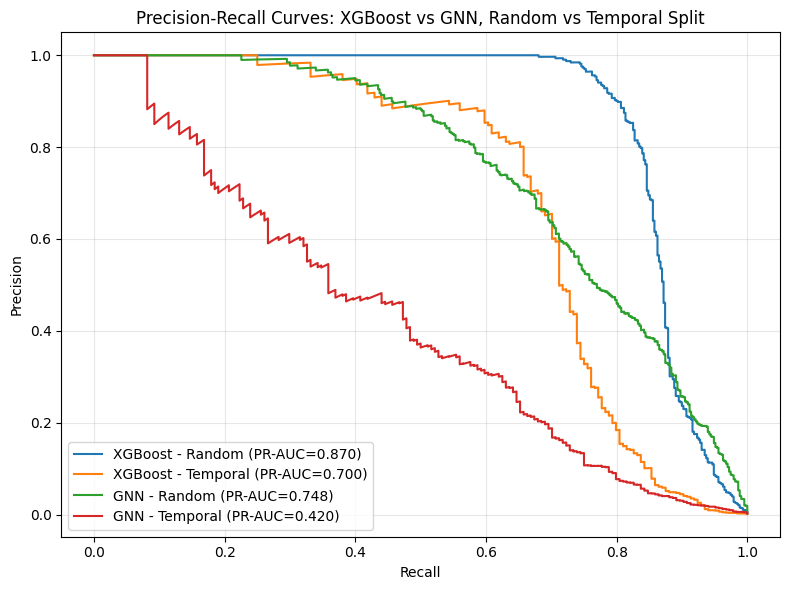

In [ ]:
# ============================================================
# PR curves for all four model/split combinations
# ============================================================
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve

fig, ax = plt.subplots(figsize=(8, 6))

# XGBoost — random split (TUNED model)
prec, rec, _ = precision_recall_curve(y_test, y_prob_tuned)
ax.plot(rec, prec, label=f'XGBoost - Random (PR-AUC={average_precision_score(y_test, y_prob_tuned):.3f})')

# XGBoost — temporal split (TUNED model)
prec_t, rec_t, _ = precision_recall_curve(y_test_temporal, y_prob_temporal_tuned)
ax.plot(rec_t, prec_t, label=f'XGBoost - Temporal (PR-AUC={average_precision_score(y_test_temporal, y_prob_temporal_tuned):.3f})')

# GNN — random split
prec_g, rec_g, _ = precision_recall_curve(test_labels, test_probs)
ax.plot(rec_g, prec_g, label=f'GNN - Random (PR-AUC={average_precision_score(test_labels, test_probs):.3f})')

# GNN — temporal split
prec_gt, rec_gt, _ = precision_recall_curve(test_labels_temporal, test_probs_temporal)
ax.plot(rec_gt, prec_gt, label=f'GNN - Temporal (PR-AUC={average_precision_score(test_labels_temporal, test_probs_temporal):.3f})')

ax.set_xlabel('Recall')
ax.set_ylabel('Precision')
ax.set_title('Precision-Recall Curves: XGBoost vs GNN, Random vs Temporal Split')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('pr_curves_final.png', dpi=150)
plt.show()

In [ ]:
# ============================================================
# Hyperparameter tuning — Random Search on XGBoost
# Uses a validation split carved out of TRAINING data only
# (never the held-out test set, to keep final results honest)
# ============================================================
from sklearn.model_selection import train_test_split
import random

# Carve a validation set out of the training data
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train, test_size=0.2, random_state=42, stratify=y_train
)

random.seed(42)
results = []

for i in range(3):
    params = {
        'max_depth': random.choice([4, 6, 8, 10]),
        'n_estimators': random.choice([100, 200, 300]),
        'learning_rate': random.choice([0.05, 0.1, 0.2])
    }
    m = XGBClassifier(
        **params,
        scale_pos_weight=(y_tr == 0).sum() / (y_tr == 1).sum(),
        eval_metric='aucpr',
        random_state=42
    )
    m.fit(X_tr, y_tr)
    val_prob = m.predict_proba(X_val)[:, 1]
    pr_auc = average_precision_score(y_val, val_prob)
    results.append((params, pr_auc))
    print(f"Trial {i+1}: {params} -> Validation PR-AUC: {pr_auc:.4f}")

Trial 1: {'max_depth': 4, 'n_estimators': 100, 'learning_rate': 0.2} -> Validation PR-AUC: 0.8552
Trial 2: {'max_depth': 8, 'n_estimators': 100, 'learning_rate': 0.05} -> Validation PR-AUC: 0.8447
Trial 3: {'max_depth': 6, 'n_estimators': 300, 'learning_rate': 0.05} -> Validation PR-AUC: 0.8895


max_depth=2 -> Validation PR-AUC: 0.6658
max_depth=3 -> Validation PR-AUC: 0.7567
max_depth=4 -> Validation PR-AUC: 0.8590
max_depth=5 -> Validation PR-AUC: 0.8849
max_depth=6 -> Validation PR-AUC: 0.8983
max_depth=7 -> Validation PR-AUC: 0.9069
max_depth=8 -> Validation PR-AUC: 0.9128
max_depth=9 -> Validation PR-AUC: 0.9171
max_depth=10 -> Validation PR-AUC: 0.9087


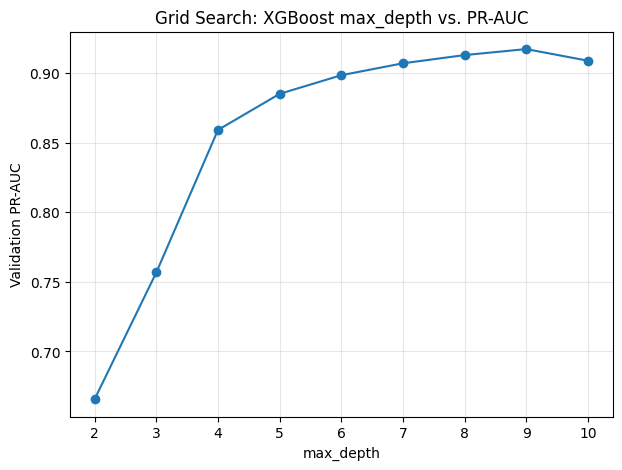

In [ ]:
# ============================================================
# Grid Search — sweep max_depth across a fixed range, plot results
# ============================================================
depth_values = list(range(2, 11))
grid_results = []

for depth in depth_values:
    m = XGBClassifier(
        n_estimators=200,
        max_depth=depth,
        learning_rate=0.1,
        scale_pos_weight=(y_tr == 0).sum() / (y_tr == 1).sum(),
        eval_metric='aucpr',
        random_state=42
    )
    m.fit(X_tr, y_tr)
    val_prob = m.predict_proba(X_val)[:, 1]
    pr_auc = average_precision_score(y_val, val_prob)
    grid_results.append(pr_auc)
    print(f"max_depth={depth} -> Validation PR-AUC: {pr_auc:.4f}")

import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))
plt.plot(depth_values, grid_results, marker='o')
plt.xlabel('max_depth')
plt.ylabel('Validation PR-AUC')
plt.title('Grid Search: XGBoost max_depth vs. PR-AUC')
plt.grid(alpha=0.3)
plt.savefig('grid_search_depth.png', dpi=150)
plt.show()

In [ ]:
# ============================================================
# Retrain final XGBoost with the tuned hyperparameter (max_depth=9)
# and re-evaluate on the REAL test set (not the validation set)
# ============================================================
model_tuned = XGBClassifier(
    n_estimators=200,
    max_depth=9,
    learning_rate=0.1,
    scale_pos_weight=(y_train == 0).sum() / (y_train == 1).sum(),
    eval_metric='aucpr',
    random_state=42
)
model_tuned.fit(X_train, y_train)

y_pred_tuned = model_tuned.predict(X_test)
y_prob_tuned = model_tuned.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred_tuned, digits=3))
print("PR-AUC (tuned, test set):", average_precision_score(y_test, y_prob_tuned))
print("ROC-AUC (tuned, test set):", roc_auc_score(y_test, y_prob_tuned))


              precision    recall  f1-score   support

           0      0.999     0.999     0.999    110715
           1      0.839     0.825     0.832       429

    accuracy                          0.999    111144
   macro avg      0.919     0.912     0.916    111144
weighted avg      0.999     0.999     0.999    111144

PR-AUC (tuned, test set): 0.87021759237899
ROC-AUC (tuned, test set): 0.99098851742125


In [ ]:
# ============================================================
# Retrain temporal XGBoost with the tuned max_depth for consistency
# ============================================================
model_temporal_tuned = XGBClassifier(
    n_estimators=200,
    max_depth=9,
    learning_rate=0.1,
    scale_pos_weight=(y_train_temporal == 0).sum() / (y_train_temporal == 1).sum(),
    eval_metric='aucpr',
    random_state=42
)
model_temporal_tuned.fit(X_train_temporal, y_train_temporal)

y_pred_temporal_tuned = model_temporal_tuned.predict(X_test_temporal)
y_prob_temporal_tuned = model_temporal_tuned.predict_proba(X_test_temporal)[:, 1]

print(classification_report(y_test_temporal, y_pred_temporal_tuned, digits=3))
print("PR-AUC (tuned, temporal):", average_precision_score(y_test_temporal, y_prob_temporal_tuned))
print("ROC-AUC (tuned, temporal):", roc_auc_score(y_test_temporal, y_prob_temporal_tuned))

              precision    recall  f1-score   support

           0      0.999     1.000     1.000    110960
           1      0.724     0.668     0.695       184

    accuracy                          0.999    111144
   macro avg      0.861     0.834     0.847    111144
weighted avg      0.999     0.999     0.999    111144

PR-AUC (tuned, temporal): 0.6997594312819179
ROC-AUC (tuned, temporal): 0.9715412036456538


Data visualization (for Section 4 — Dataset)

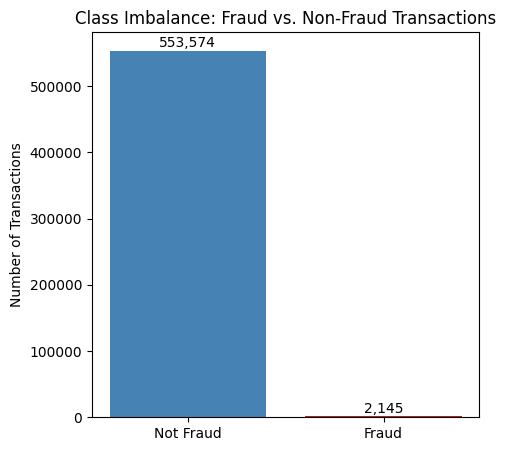

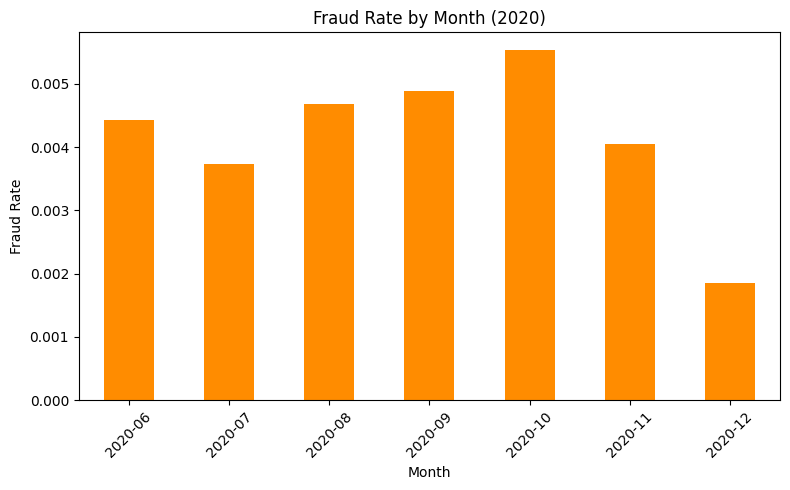

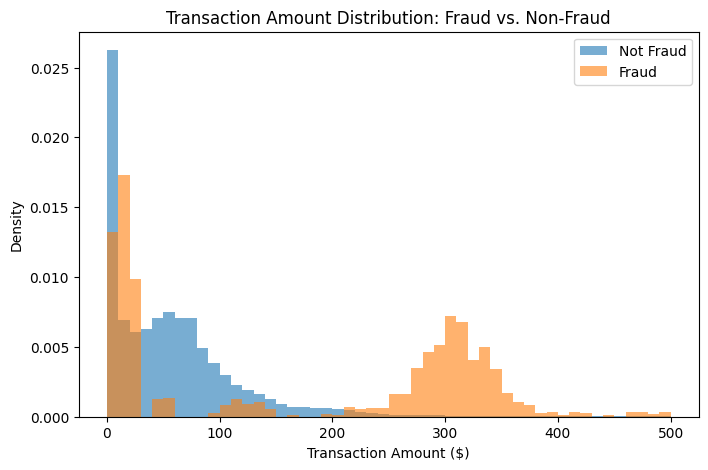

In [ ]:
# ============================================================
# Data viz — class imbalance bar chart
# ============================================================
import matplotlib.pyplot as plt

fraud_counts = df['is_fraud'].value_counts()
plt.figure(figsize=(5, 5))
plt.bar(['Not Fraud', 'Fraud'], fraud_counts.values, color=['steelblue', 'firebrick'])
plt.ylabel('Number of Transactions')
plt.title('Class Imbalance: Fraud vs. Non-Fraud Transactions')
for i, v in enumerate(fraud_counts.values):
    plt.text(i, v + 5000, f'{v:,}', ha='center')
plt.savefig('class_imbalance.png', dpi=150)
plt.show()

# ============================================================
# Data viz — fraud rate by month (shows the temporal shift visually)
# ============================================================
monthly_fraud = df.groupby(df['trans_date_trans_time'].dt.to_period('M'))['is_fraud'].mean()
plt.figure(figsize=(8, 5))
monthly_fraud.plot(kind='bar', color='darkorange')
plt.ylabel('Fraud Rate')
plt.xlabel('Month')
plt.title('Fraud Rate by Month (2020)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('fraud_rate_by_month.png', dpi=150)
plt.show()

# ============================================================
# Data viz — transaction amount distribution, fraud vs. non-fraud
# ============================================================
plt.figure(figsize=(8, 5))
plt.hist(df[df['is_fraud']==0]['amt'], bins=50, alpha=0.6, label='Not Fraud', range=(0, 500), density=True)
plt.hist(df[df['is_fraud']==1]['amt'], bins=50, alpha=0.6, label='Fraud', range=(0, 500), density=True)
plt.xlabel('Transaction Amount ($)')
plt.ylabel('Density')
plt.title('Transaction Amount Distribution: Fraud vs. Non-Fraud')
plt.legend()
plt.savefig('amount_distribution.png', dpi=150)
plt.show()

Confusion matrix + ROC curve (for Section 6.1)

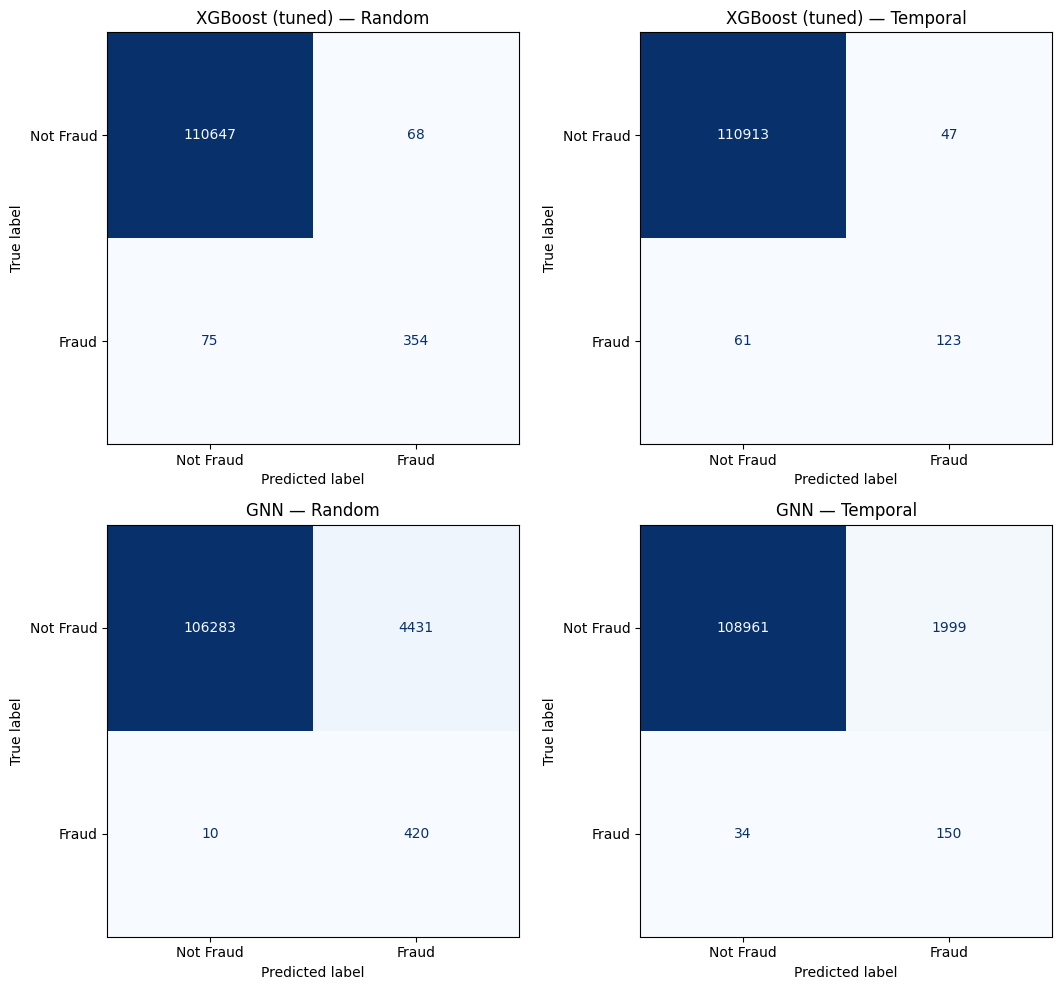

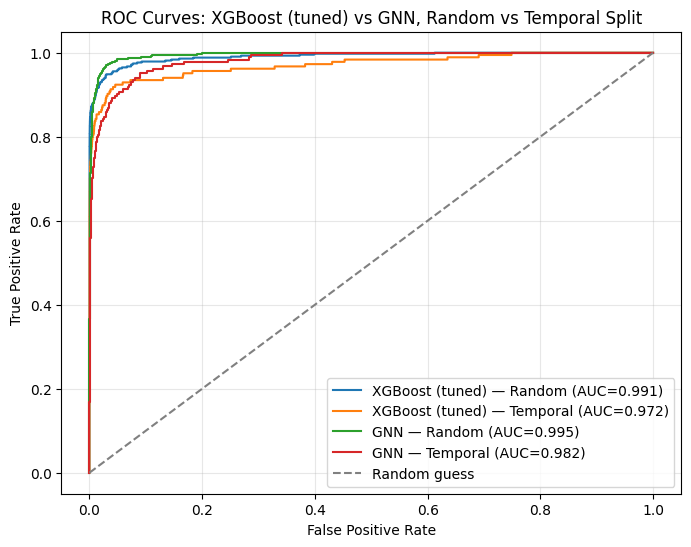

In [ ]:
# ============================================================
# Fixed: confusion matrices using the TUNED XGBoost model
# ============================================================
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, roc_curve

fig, axes = plt.subplots(2, 2, figsize=(11, 10))

configs = [
    (y_test, y_pred_tuned, "XGBoost (tuned) — Random"),
    (y_test_temporal, y_pred_temporal_tuned, "XGBoost (tuned) — Temporal"),
    (test_labels, test_preds, "GNN — Random"),
    (test_labels_temporal, test_preds_temporal, "GNN — Temporal"),
]

for ax, (true, pred, title) in zip(axes.flat, configs):
    cm = confusion_matrix(true, pred)
    disp = ConfusionMatrixDisplay(cm, display_labels=['Not Fraud', 'Fraud'])
    disp.plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(title)

plt.tight_layout()
plt.savefig('confusion_matrices_final.png', dpi=150)
plt.show()

# ============================================================
# Fixed: ROC curves using the TUNED XGBoost model
# ============================================================
plt.figure(figsize=(8, 6))

roc_configs = [
    (y_test, y_prob_tuned, "XGBoost (tuned) — Random"),
    (y_test_temporal, y_prob_temporal_tuned, "XGBoost (tuned) — Temporal"),
    (test_labels, test_probs, "GNN — Random"),
    (test_labels_temporal, test_probs_temporal, "GNN — Temporal"),
]

for true, prob, label in roc_configs:
    fpr, tpr, _ = roc_curve(true, prob)
    auc = roc_auc_score(true, prob)
    plt.plot(fpr, tpr, label=f'{label} (AUC={auc:.3f})')

plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves: XGBoost (tuned) vs GNN, Random vs Temporal Split')
plt.legend()
plt.grid(alpha=0.3)
plt.savefig('roc_curves_final.png', dpi=150)
plt.show()

In [ ]:
# ============================================================
# Get PR-AUC for THIS final GNN run, to match the images above
# ============================================================
print("GNN Random PR-AUC:", average_precision_score(test_labels, test_probs))
print("GNN Temporal PR-AUC:", average_precision_score(test_labels_temporal, test_probs_temporal))

GNN Random PR-AUC: 0.7477135804126156
GNN Temporal PR-AUC: 0.4204967132441375


In [ ]:
def run_temporal_gnn(structure_edges, seed, epochs=200):
    torch.manual_seed(seed)
    m = FraudGraphSAGE(
        node_in_channels=temporal_x.shape[1],
        edge_in_channels=temporal_edge_attr.shape[1],
        hidden_channels=64
    ).to(device)
    opt = torch.optim.Adam(m.parameters(), lr=0.005, weight_decay=5e-4)
    crit = nn.CrossEntropyLoss(weight=class_weights_temporal)

    for epoch in range(1, epochs + 1):
        m.train()
        opt.zero_grad()
        out = m(temporal_data.x, structure_edges, temporal_data.edge_index, temporal_data.edge_attr)
        loss = crit(out[temporal_data.train_mask], temporal_data.edge_label[temporal_data.train_mask])
        loss.backward()
        opt.step()
        if epoch % 50 == 0:
            print(f"  seed {seed} | epoch {epoch} | loss {loss.item():.4f}")

    m.eval()
    with torch.no_grad():
        out = m(temporal_data.x, structure_edges, temporal_data.edge_index, temporal_data.edge_attr)
        p = F.softmax(out, dim=1)[:, 1][temporal_data.test_mask].cpu().numpy()
    y = temporal_data.edge_label[temporal_data.test_mask].cpu().numpy()
    return average_precision_score(y, p), roc_auc_score(y, p)

# Current setup: message passing over ALL edges (includes test-period connectivity)
full_edges = temporal_data.structure_edge_index

# Strict setup: message passing over TRAINING-period edges only
strict_edges = to_undirected(edge_index[:, temporal_train_mask.cpu()]).to(device)

print("Full-graph edges:", full_edges.shape[1], "| Strict edges:", strict_edges.shape[1])

results = {"full graph (current)": [], "training-period graph only (strict)": []}
for seed in [0, 1, 2]:
    print(f"--- seed {seed}: full graph ---")
    results["full graph (current)"].append(run_temporal_gnn(full_edges, seed))
    print(f"--- seed {seed}: strict graph ---")
    results["training-period graph only (strict)"].append(run_temporal_gnn(strict_edges, seed))

for name, runs in results.items():
    pr = [r[0] for r in runs]
    roc = [r[1] for r in runs]
    print(f"\n{name}")
    print(f"  PR-AUC:  mean {np.mean(pr):.3f}, std {np.std(pr):.3f}, runs {[round(x, 3) for x in pr]}")
    print(f"  ROC-AUC: mean {np.mean(roc):.3f}, std {np.std(roc):.3f}")

Full-graph edges: 656792 | Strict edges: 574654
--- seed 0: full graph ---


KeyboardInterrupt: 

In [ ]:
def run_random_gnn(structure_edges, seed, epochs=200):
    torch.manual_seed(seed)
    m = FraudGraphSAGE(
        node_in_channels=data.x.shape[1],
        edge_in_channels=data.edge_attr.shape[1],
        hidden_channels=64
    ).to(device)
    opt = torch.optim.Adam(m.parameters(), lr=0.005, weight_decay=5e-4)
    crit = nn.CrossEntropyLoss(weight=class_weights)

    for epoch in range(1, epochs + 1):
        m.train()
        opt.zero_grad()
        out = m(data.x, structure_edges, data.edge_index, data.edge_attr)
        loss = crit(out[data.train_mask], data.edge_label[data.train_mask])
        loss.backward()
        opt.step()
        if epoch % 50 == 0:
            print(f"  seed {seed} | epoch {epoch} | loss {loss.item():.4f}")

    m.eval()
    with torch.no_grad():
        out = m(data.x, structure_edges, data.edge_index, data.edge_attr)
        p = F.softmax(out, dim=1)[:, 1][data.test_mask].cpu().numpy()
    y = data.edge_label[data.test_mask].cpu().numpy()
    return average_precision_score(y, p), roc_auc_score(y, p)

directed_edges = data.edge_index              # customer -> merchant only
undirected_edges = data.structure_edge_index  # both directions

results = {"directed only": [], "undirected (current)": []}
for seed in [0, 1, 2]:
    print(f"--- seed {seed}: directed only ---")
    results["directed only"].append(run_random_gnn(directed_edges, seed))
    print(f"--- seed {seed}: undirected ---")
    results["undirected (current)"].append(run_random_gnn(undirected_edges, seed))

for name, runs in results.items():
    pr = [r[0] for r in runs]
    roc = [r[1] for r in runs]
    print(f"\n{name}")
    print(f"  PR-AUC:  mean {np.mean(pr):.3f}, std {np.std(pr):.3f}, runs {[round(float(x), 3) for x in pr]}")
    print(f"  ROC-AUC: mean {np.mean(roc):.3f}, std {np.std(roc):.3f}")

In [ ]:
# ============================================================
# Corrected qualitative comparison (random split)
# - GNN probabilities come from the RANDOM-split model, not `probs`
#   (the temporal evaluation overwrote `probs`)
# - XGBoost probabilities come from the TUNED model
# ============================================================
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from sklearn.metrics import average_precision_score

# 1. Fresh probabilities from the random-split GNN
model.eval()
with torch.no_grad():
    out_random = model(data.x, data.structure_edge_index, data.edge_index, data.edge_attr)
    probs_random = F.softmax(out_random, dim=1)[:, 1].cpu().numpy()

print("Old `probs` equals random-split GNN output?:", np.allclose(probs.cpu().numpy(), probs_random))
test_pos = np.where(data.test_mask.cpu().numpy())[0]
print("Random-split GNN PR-AUC (should be about 0.748):",
      average_precision_score(data.edge_label[data.test_mask].cpu().numpy(), probs_random[test_pos]))

# 2. Align tuned XGBoost predictions with df row positions using the composite key
key_cols = ['cc_num', 'trans_date_trans_time', 'amt', 'merchant']
df_key = df[key_cols].copy()
df_key['row_position'] = np.arange(len(df))

test_key = test_df[key_cols].copy()
test_key['xgb_prob'] = y_prob_tuned          # tuned XGBoost
test_key['true_label'] = y_test.values
merged = test_key.merge(df_key, on=key_cols, how='left')
assert len(merged) == len(test_df), "composite key matched more than one row"
merged['row_position'] = merged['row_position'].astype(int)

merged['gnn_prob'] = probs_random[merged['row_position'].values]
merged['gnn_label'] = data.edge_label.cpu().numpy()[merged['row_position'].values]
print("Labels agree:", (merged['true_label'].values == merged['gnn_label']).all())

# 3. Four-way breakdown at a 0.5 threshold
fraud = merged[merged['true_label'] == 1].copy()
x_hit = fraud['xgb_prob'] > 0.5
g_hit = fraud['gnn_prob'] > 0.5
print("\nTotal fraud cases in test set:", len(fraud))
print("Both models caught:", (x_hit & g_hit).sum())
print("GNN caught, XGBoost missed:", (~x_hit & g_hit).sum())
print("XGBoost caught, GNN missed:", (x_hit & ~g_hit).sum())
print("Both missed:", (~x_hit & ~g_hit).sum())

# 4. Hypothesis checks
gnn_only = fraud[~x_hit & g_hit]
xgb_only = fraud[x_hit & ~g_hit]
print("\nMedian amount | GNN-only:", gnn_only['amt'].median(),
      "| XGBoost-only:", xgb_only['amt'].median(),
      "| all fraud:", fraud['amt'].median())

gnn_only = gnn_only.merge(merchant_stats[['merchant', 'merchant_fraud_rate']], on='merchant', how='left')
print("GNN-only catches at merchants with 0% training fraud rate:",
      (gnn_only['merchant_fraud_rate'] == 0).sum(), "of", len(gnn_only))

gnn_only_cards = gnn_only.merge(card_stats, on='cc_num', how='left')
print("\nMedian card activity, GNN-only catches:")
print(gnn_only_cards[['card_txn_count', 'card_unique_merchants']].median())
print("Median card activity, all customers:")
print(card_stats[['card_txn_count', 'card_unique_merchants']].median())

In [ ]:
needed = ['df', 'test_df', 'y_test', 'y_prob_tuned', 'model', 'data',
          'merchant_stats', 'card_stats', 'device']
for v in needed:
    print(v, 'exists:', v in globals())

print("model type (should be FraudGraphSAGE):", type(model).__name__)
print("data test edges (should be 111144):", data.test_mask.sum().item())
print("data test fraud (should be 430):", data.edge_label[data.test_mask].sum().item())

In [ ]:
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (average_precision_score, roc_auc_score,
                             precision_score, recall_score, confusion_matrix)

# ---- 1. Recreate the ORIGINAL random split (same call as Step 7) ----
orig_train, orig_test = train_test_split(
    df, test_size=0.2, random_state=42, stratify=df['is_fraud']
)
n = len(df)
assert (df.index.values == np.arange(n)).all(), "df index is not 0..n-1"
assert len(orig_test) == len(y_test)
assert np.array_equal(orig_test['is_fraud'].values, y_test.values), "split does not match XGBoost's test set"
assert np.allclose(orig_test['amt'].values, test_df['amt'].values), "amounts do not match XGBoost's test set"

# ---- 2. Correct masks (df index labels == row positions) ----
train_np = np.zeros(n, dtype=bool); train_np[orig_train.index.values] = True
test_np  = np.zeros(n, dtype=bool); test_np[orig_test.index.values] = True
assert not (train_np & test_np).any(), "masks still overlap"
assert (train_np | test_np).all()
data.train_mask = torch.tensor(train_np).to(device)
data.test_mask  = torch.tensor(test_np).to(device)
print("Overlap now (must be 0):", int((data.train_mask & data.test_mask).sum()))
print("Train / test sizes:", int(data.train_mask.sum()), int(data.test_mask.sum()))
print("Fraud in GNN test mask (must be 429):", int(data.edge_label[data.test_mask].sum()))

# ---- 3. Refit the edge scaler on the TRUE training rows ----
edge_scaler = StandardScaler().fit(df.loc[orig_train.index, edge_feature_cols].values)
data.edge_attr = torch.tensor(
    edge_scaler.transform(df[edge_feature_cols].values), dtype=torch.float
).to(device)

# ---- 4. Class weights from the true training edges ----
y_all_t = data.edge_label
cw = torch.tensor(
    [1.0, (y_all_t[data.train_mask] == 0).sum().item() /
          (y_all_t[data.train_mask] == 1).sum().item()],
    dtype=torch.float).to(device)
print("Class weights:", cw)

# ---- 5. Clean 200-epoch training function ----
def run_random_gnn_fixed(structure_edges, seed, epochs=200):
    torch.manual_seed(seed); np.random.seed(seed)
    m = FraudGraphSAGE(node_in_channels=data.x.shape[1],
                       edge_in_channels=data.edge_attr.shape[1],
                       hidden_channels=64).to(device)
    opt = torch.optim.Adam(m.parameters(), lr=0.005, weight_decay=5e-4)
    crit = nn.CrossEntropyLoss(weight=cw)
    for epoch in range(1, epochs + 1):
        m.train(); opt.zero_grad()
        out = m(data.x, structure_edges, data.edge_index, data.edge_attr)
        loss = crit(out[data.train_mask], data.edge_label[data.train_mask])
        loss.backward(); opt.step()
    m.eval()
    with torch.no_grad():
        out = m(data.x, structure_edges, data.edge_index, data.edge_attr)
        p = F.softmax(out, dim=1)[:, 1].cpu().numpy()
    return m, p

y_all = data.edge_label.cpu().numpy()
test_pos = np.where(test_np)[0]
y_te = y_all[test_pos]

def metrics(p_all):
    p = p_all[test_pos]
    pred = (p >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_te, pred).ravel()
    return dict(pr=average_precision_score(y_te, p), roc=roc_auc_score(y_te, p),
                rec=recall_score(y_te, pred), prec=precision_score(y_te, pred, zero_division=0),
                fp=int(fp), tp=int(tp))

# ---- 6. Five seeds, undirected (main model) and directed ----
setups = {"undirected (main)": data.structure_edge_index, "directed only": data.edge_index}
res = {k: [] for k in setups}
models0, probs0 = {}, {}
for name, edges in setups.items():
    for seed in range(5):
        print(f"{name} | seed {seed}")
        m, p = run_random_gnn_fixed(edges, seed)
        res[name].append(metrics(p))
        if seed == 0:
            models0[name], probs0[name] = m, p

print("\n===== CORRECTED GNN, RANDOM SPLIT (true held-out test) =====")
for name, runs in res.items():
    pr = [r['pr'] for r in runs]
    print(f"\n{name}")
    print(f"  PR-AUC : mean {np.mean(pr):.3f}  std {np.std(pr):.3f}  runs {[round(x,3) for x in pr]}")
    for key in ['roc', 'rec', 'prec']:
        v = [r[key] for r in runs]
        print(f"  {key:5s}  : mean {np.mean(v):.3f}  std {np.std(v):.3f}")
    print("  FP / TP (seed 0):", runs[0]['fp'], "/", runs[0]['tp'])

# ---- 7. Make the old plotting and qualitative cells use the corrected seed-0 model ----
model = models0["undirected (main)"]
probs_random = probs0["undirected (main)"]
probs = torch.tensor(probs_random)
test_labels = y_te
test_probs = probs_random[test_pos]
test_preds = (test_probs >= 0.5).astype(int)
print("\nSeed-0 undirected PR-AUC (this is the one the figures will use):",
      average_precision_score(test_labels, test_probs))